<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_3_SQL/Projects/Instructions/Project.3-SQL/SQL_1_Chinook_Phase_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project SQL: Data Discovery with the Chinook Database

Welcome to your first major hands-on data exploration project. In this assignment, you will be stepping into the role of a data analyst querying the Chinook database: a sample dataset representing a digital media store, complete with information about artists, albums, tracks, customers, and business sales.

The core objective of this project is to transition you from simply writing code to thinking like a data scientist. To do that, our journey follows a deliberate, four-fold progression:



### Phase 4. Ask and Answer Your Own Questions


This final phase is the most critical part of the project. The true hallmark of a great data scientist isn't just answering the questions you're handed; it's having the curiosity and intuition to formulate your own questions.

You are tasked with looking at the Chinook dataset, generating your own original hypotheses or business questions, and writing the SQL required to answer them.

Demonstrate that you know SQL fundamentals by posting a question for each SQL statement below and then using the SQL statement to answer you question.

You will use the material from this phase for the presentation.



## Load the Chinook data set

See the lecture on SQLite3 using the Chinook data set to set up the software, database, and tables, as well as for the links to ancillary information about the data set.


In [1]:
# Import libraries
import sqlite3 as db
import pandas as pd
import contextlib
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import seaborn as sns

In [4]:
# Install the sqlite package for Ubuntu
%%capture
%%bash
apt-get update
apt-get install -y sqlite3


In [5]:
# Download chinook.zip silently (-s) if it does not already exist in the current directory
%%bash
[ -f chinook.zip ] ||
  curl -s -O https://www.sqlitetutorial.net/wp-content/uploads/2018/03/chinook.zip
# List (-l) the contents of the downloaded zip archive without extracting it yet
unzip -l chinook.zip


Archive:  chinook.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
   884736  2015-11-29 10:53   chinook.db
---------                     -------
   884736                     1 file


In [6]:
# Force-remove any existing chinook.db file to ensure a clean extraction
!rm -f chinook.db


In [7]:
# Unzip chinook.zip (-u updates/creates files) to extract chinook.db into the working directory
!unzip -u chinook.zip


Archive:  chinook.zip
  inflating: chinook.db              


In [8]:
# List all files in the current directory with detailed permissions, sizes, and timestamps
!ls -l

total 1168
-rw-r--r-- 1 root root 884736 Nov 29  2015 chinook.db
-rw-r--r-- 1 root root 305596 Nov 17 02:36 chinook.zip
drwxr-xr-x 1 root root   4096 Oct 26 22:18 sample_data


In [9]:
# Confirm specifically that the .db file exists and check its file size
!ls -l *.db

-rw-r--r-- 1 root root 884736 Nov 29  2015 chinook.db


# Business Question: What drives sales, and where might the store have opportunities?




## Chapter 1: When and where do sales happen?

### 1. Are there months or years when sales are consistently higher?


In [8]:
%%script sqlite3 --column --header chinook.db
SELECT
    strftime('%Y', InvoiceDate) AS Year,
    strftime('%m', InvoiceDate) AS Month,
    COUNT(*) AS InvoiceCount,
    ROUND(SUM(Total), 2) AS Revenue,
    ROUND(AVG(Total), 2) AS AvgInvoiceValue
FROM invoices
GROUP BY Year, Month
ORDER BY Year, Month;

Year  Month  InvoiceCount  Revenue  AvgInvoiceValue
----  -----  ------------  -------  ---------------
2009  01     6             35.64    5.94           
2009  02     7             37.62    5.37           
2009  03     7             37.62    5.37           
2009  04     7             37.62    5.37           
2009  05     7             37.62    5.37           
2009  06     7             37.62    5.37           
2009  07     7             37.62    5.37           
2009  08     7             37.62    5.37           
2009  09     7             37.62    5.37           
2009  10     7             37.62    5.37           
2009  11     7             37.62    5.37           
2009  12     7             37.62    5.37           
2010  01     7             52.62    7.52           
2010  02     7             46.62    6.66           
2010  03     7             44.62    6.37           
2010  04     7             37.62    5.37           
2010  05     7             37.62    5.37           
2010  06    

### 2. Does average invoice value differ across billing countries?

In [ ]:
%%script sqlite3 --column --header chinook.db
SELECT
    BillingCountry,
    COUNT(*) AS InvoiceCount,
    COUNT(DISTINCT CustomerId) AS CustomerCount,
    ROUND(SUM(Total), 2) AS Revenue,
    ROUND(AVG(Total), 2) AS AvgInvoiceValue,
    ROUND(MIN(Total), 2) AS SmallestInvoice,
    ROUND(MAX(Total), 2) AS LargestInvoice
FROM invoices
GROUP BY BillingCountry
ORDER BY AvgInvoiceValue DESC, BillingCountry;

### 3. Which genres are most popular in each billing country?

Now that we’ve seen when and where purchases happen, let’s look more closely at the products customers buy.

In [9]:
%%script sqlite3 --column --header chinook.db
WITH country_genre_sales AS (
    SELECT
        i.BillingCountry,
        g.GenreId,
        g.Name AS Genre,
        SUM(ii.Quantity) AS UnitsSold,
        ROUND(SUM(ii.UnitPrice * ii.Quantity), 2) AS Revenue
    FROM invoices AS i
    JOIN invoice_items AS ii
        ON ii.InvoiceId = i.InvoiceId
    JOIN tracks AS t
        ON t.TrackId = ii.TrackId
    JOIN genres AS g
        ON g.GenreId = t.GenreId
    GROUP BY i.BillingCountry, g.GenreId, g.Name
),
ranked_genres AS (
    SELECT
        *,
        DENSE_RANK() OVER (
            PARTITION BY BillingCountry
            ORDER BY UnitsSold DESC
        ) AS PopularityRank
    FROM country_genre_sales
)
SELECT
    BillingCountry,
    Genre,
    UnitsSold,
    Revenue
FROM ranked_genres
WHERE PopularityRank = 1
ORDER BY BillingCountry, Genre;

BillingCountry  Genre               UnitsSold  Revenue
--------------  ------------------  ---------  -------
Argentina       Alternative & Punk  9          8.91   
Argentina       Rock                9          8.91   
Australia       Rock                22         21.78  
Austria         Rock                15         14.85  
Belgium         Rock                21         20.79  
Brazil          Rock                81         80.19  
Canada          Rock                107        105.93 
Chile           Rock                9          8.91   
Czech Republic  Rock                25         24.75  
Denmark         Rock                21         20.79  
Finland         Rock                18         17.82  
France          Rock                65         64.35  
Germany         Rock                62         61.38  
Hungary         Rock                11         10.89  
India           Rock                25         24.75  
Ireland         Rock                12         11.88  
Italy     

## Chapter 2: What sells and what doesn’t?

### 4. Which genres generate the most revenue, and do they rank the same way by units sold?

In [10]:
%%script sqlite3 --column --header chinook.db
WITH genre_sales AS (
    SELECT
        g.GenreId,
        g.Name AS Genre,
        SUM(ii.Quantity) AS UnitsSold,
        SUM(ii.UnitPrice * ii.Quantity) AS Revenue
    FROM invoice_items AS ii
    JOIN tracks AS t
        ON t.TrackId = ii.TrackId
    JOIN genres AS g
        ON g.GenreId = t.GenreId
    GROUP BY g.GenreId, g.Name
)
SELECT
    Genre,
    UnitsSold,
    ROUND(Revenue, 2) AS Revenue,
    DENSE_RANK() OVER (
        ORDER BY UnitsSold DESC
    ) AS UnitsRank,
    DENSE_RANK() OVER (
        ORDER BY Revenue DESC
    ) AS RevenueRank
FROM genre_sales
ORDER BY Revenue DESC, Genre;

Genre               UnitsSold  Revenue  UnitsRank  RevenueRank
------------------  ---------  -------  ---------  -----------
Rock                835        826.65   1          1          
Latin               386        382.14   2          2          
Metal               264        261.36   3          3          
Alternative & Punk  244        241.56   4          4          
TV Shows            47         93.53    7          5          
Jazz                80         79.2     5          6          
Blues               61         60.39    6          7          
Drama               29         57.71    10         8          
Classical           41         40.59    8          9          
R&B/Soul            41         40.59    8          9          
Sci Fi & Fantasy    20         39.8     12         10         
Reggae              30         29.7     9          11         
Pop                 28         27.72    11         12         
Soundtrack          20         19.8     12         13  

### 5. Which artists have the largest catalogs, and are they also among the highest-selling artists?

In [ ]:
%%script sqlite3 --column --header chinook.db
WITH artist_catalog AS (
    SELECT
        ar.ArtistId,
        ar.Name AS Artist,
        COUNT(DISTINCT al.AlbumId) AS AlbumCount,
        COUNT(t.TrackId) AS CatalogTracks
    FROM artists AS ar
    LEFT JOIN albums AS al
        ON al.ArtistId = ar.ArtistId
    LEFT JOIN tracks AS t
        ON t.AlbumId = al.AlbumId
    GROUP BY ar.ArtistId, ar.Name
),
artist_sales AS (
    SELECT
        al.ArtistId,
        SUM(ii.Quantity) AS UnitsSold,
        SUM(ii.UnitPrice * ii.Quantity) AS Revenue
    FROM albums AS al
    JOIN tracks AS t
        ON t.AlbumId = al.AlbumId
    JOIN invoice_items AS ii
        ON ii.TrackId = t.TrackId
    GROUP BY al.ArtistId
)
SELECT
    ac.Artist,
    ac.AlbumCount,
    ac.CatalogTracks,
    COALESCE(s.UnitsSold, 0) AS UnitsSold,
    ROUND(COALESCE(s.Revenue, 0), 2) AS Revenue,
    DENSE_RANK() OVER (
        ORDER BY ac.CatalogTracks DESC
    ) AS CatalogRank,
    DENSE_RANK() OVER (
        ORDER BY COALESCE(s.UnitsSold, 0) DESC
    ) AS UnitsSoldRank
FROM artist_catalog AS ac
LEFT JOIN artist_sales AS s
    ON s.ArtistId = ac.ArtistId
ORDER BY CatalogRank, ac.Artist;

### 6. Which albums contain the greatest number of distinct tracks that have been purchased?

In [ ]:
%%script sqlite3 --column --header chinook.db
WITH purchased_tracks AS (
    SELECT DISTINCT TrackId
    FROM invoice_items
)
SELECT
    al.Title AS Album,
    ar.Name AS Artist,
    COUNT(t.TrackId) AS TotalTracks,
    COUNT(pt.TrackId) AS PurchasedTracks,
    ROUND(
        100.0 * COUNT(pt.TrackId)
        / NULLIF(COUNT(t.TrackId), 0),
        2
    ) AS PctTracksPurchased
FROM albums AS al
JOIN artists AS ar
    ON ar.ArtistId = al.ArtistId
JOIN tracks AS t
    ON t.AlbumId = al.AlbumId
LEFT JOIN purchased_tracks AS pt
    ON pt.TrackId = t.TrackId
GROUP BY al.AlbumId, al.Title, ar.Name
ORDER BY PurchasedTracks DESC, PctTracksPurchased DESC, Album;

### 7. What percentage of the catalog has never been purchased?

In [ ]:
%%script sqlite3 --column --header chinook.db
WITH purchased_tracks AS (
    SELECT DISTINCT TrackId
    FROM invoice_items
)
SELECT
    COUNT(*) AS TotalCatalogTracks,
    COUNT(pt.TrackId) AS PurchasedTracks,
    COUNT(*) - COUNT(pt.TrackId) AS NeverPurchasedTracks,
    ROUND(
        100.0 * (COUNT(*) - COUNT(pt.TrackId))
        / NULLIF(COUNT(*), 0),
        2
    ) AS PctNeverPurchased
FROM tracks AS t
LEFT JOIN purchased_tracks AS pt
    ON pt.TrackId = t.TrackId;

### 8. Which playlists contain the highest proportion of tracks that have been purchased at least once?

We’ve looked at the catalog as a whole. Next, let’s see how customers differ in what and how they buy.

In [ ]:
%%script sqlite3 --column --header chinook.db
WITH purchased_tracks AS (
    SELECT DISTINCT TrackId
    FROM invoice_items
)
SELECT
    COUNT(*) AS TotalCatalogTracks,
    COUNT(pt.TrackId) AS PurchasedTracks,
    COUNT(*) - COUNT(pt.TrackId) AS NeverPurchasedTracks,
    ROUND(
        100.0 * (COUNT(*) - COUNT(pt.TrackId))
        / NULLIF(COUNT(*), 0),
        2
    ) AS PctNeverPurchased
FROM tracks AS t
LEFT JOIN purchased_tracks AS pt
    ON pt.TrackId = t.TrackId;

## Chapter 3: How do buying habits differ?

### 9. Do customers who place more orders also spend more per order?

In [ ]:
%%script sqlite3 --column --header chinook.db
SELECT
    c.CustomerId,
    c.FirstName || ' ' || c.LastName AS Customer,
    c.Country,
    COUNT(i.InvoiceId) AS InvoiceCount,
    ROUND(COALESCE(SUM(i.Total), 0), 2) AS TotalSpent,
    ROUND(AVG(i.Total), 2) AS AvgInvoiceValue
FROM customers AS c
LEFT JOIN invoices AS i
    ON i.CustomerId = c.CustomerId
GROUP BY
    c.CustomerId,
    c.FirstName,
    c.LastName,
    c.Country
ORDER BY InvoiceCount DESC, AvgInvoiceValue DESC, c.CustomerId;

### 10. How long is the gap between each customer’s first and most recent purchase?

In [ ]:
%%script sqlite3 --column --header chinook.db
SELECT
    c.CustomerId,
    c.FirstName || ' ' || c.LastName AS Customer,
    COUNT(i.InvoiceId) AS InvoiceCount,
    DATE(MIN(i.InvoiceDate)) AS FirstPurchase,
    DATE(MAX(i.InvoiceDate)) AS MostRecentPurchase,
    ROUND(
        julianday(MAX(i.InvoiceDate))
        - julianday(MIN(i.InvoiceDate)),
        1
    ) AS PurchaseSpanDays
FROM customers AS c
LEFT JOIN invoices AS i
    ON i.CustomerId = c.CustomerId
GROUP BY
    c.CustomerId,
    c.FirstName,
    c.LastName
ORDER BY PurchaseSpanDays DESC, c.CustomerId;

### 11. Which customers have purchased from the widest variety of genres?

Finally, can we connect those customer patterns to the store’s sales-support structure?

In [ ]:
%%script sqlite3 --column --header chinook.db
SELECT
    c.CustomerId,
    c.FirstName || ' ' || c.LastName AS Customer,
    c.Country,
    COUNT(DISTINCT t.GenreId) AS DistinctGenres,
    COUNT(DISTINCT ii.TrackId) AS DistinctTracks,
    COALESCE(SUM(ii.Quantity), 0) AS UnitsPurchased
FROM customers AS c
LEFT JOIN invoices AS i
    ON i.CustomerId = c.CustomerId
LEFT JOIN invoice_items AS ii
    ON ii.InvoiceId = i.InvoiceId
LEFT JOIN tracks AS t
    ON t.TrackId = ii.TrackId
GROUP BY
    c.CustomerId,
    c.FirstName,
    c.LastName,
    c.Country
ORDER BY DistinctGenres DESC, DistinctTracks DESC, c.CustomerId;

## Chapter 4: Customer variety by sales agent

### 12. Which sales agents’ assigned customers purchase the widest range of genres?

In [ ]:
%%script sqlite3 --column --header chinook.db
WITH customer_genre_counts AS (
    SELECT
        c.CustomerId,
        c.SupportRepId,
        COUNT(DISTINCT t.GenreId) AS DistinctGenres
    FROM customers AS c
    LEFT JOIN invoices AS i
        ON i.CustomerId = c.CustomerId
    LEFT JOIN invoice_items AS ii
        ON ii.InvoiceId = i.InvoiceId
    LEFT JOIN tracks AS t
        ON t.TrackId = ii.TrackId
    GROUP BY c.CustomerId, c.SupportRepId
),
agent_customer_summary AS (
    SELECT
        SupportRepId,
        COUNT(*) AS AssignedCustomers,
        AVG(DistinctGenres) AS AvgGenresPerCustomer
    FROM customer_genre_counts
    GROUP BY SupportRepId
),
agent_genre_totals AS (
    SELECT
        c.SupportRepId,
        COUNT(DISTINCT t.GenreId) AS CombinedDistinctGenres
    FROM customers AS c
    LEFT JOIN invoices AS i
        ON i.CustomerId = c.CustomerId
    LEFT JOIN invoice_items AS ii
        ON ii.InvoiceId = i.InvoiceId
    LEFT JOIN tracks AS t
        ON t.TrackId = ii.TrackId
    GROUP BY c.SupportRepId
)
SELECT
    e.FirstName || ' ' || e.LastName AS SalesAgent,
    COALESCE(acs.AssignedCustomers, 0) AS AssignedCustomers,
    COALESCE(agt.CombinedDistinctGenres, 0) AS CombinedDistinctGenres,
    ROUND(acs.AvgGenresPerCustomer, 2) AS AvgGenresPerCustomer
FROM employees AS e
LEFT JOIN agent_customer_summary AS acs
    ON acs.SupportRepId = e.EmployeeId
LEFT JOIN agent_genre_totals AS agt
    ON agt.SupportRepId = e.EmployeeId
WHERE e.Title = 'Sales Support Agent'
ORDER BY
    CombinedDistinctGenres DESC,
    AvgGenresPerCustomer DESC,
    SalesAgent;

## Data Visualization




In [10]:
conn = db.connect("file:chinook.db?mode=ro", uri=True)

plt.rcParams.update({
    "figure.figsize": (11, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 16,
    "axes.labelsize": 12,
    "font.size": 11
})

Sales Patterns: When and where do sales happen?

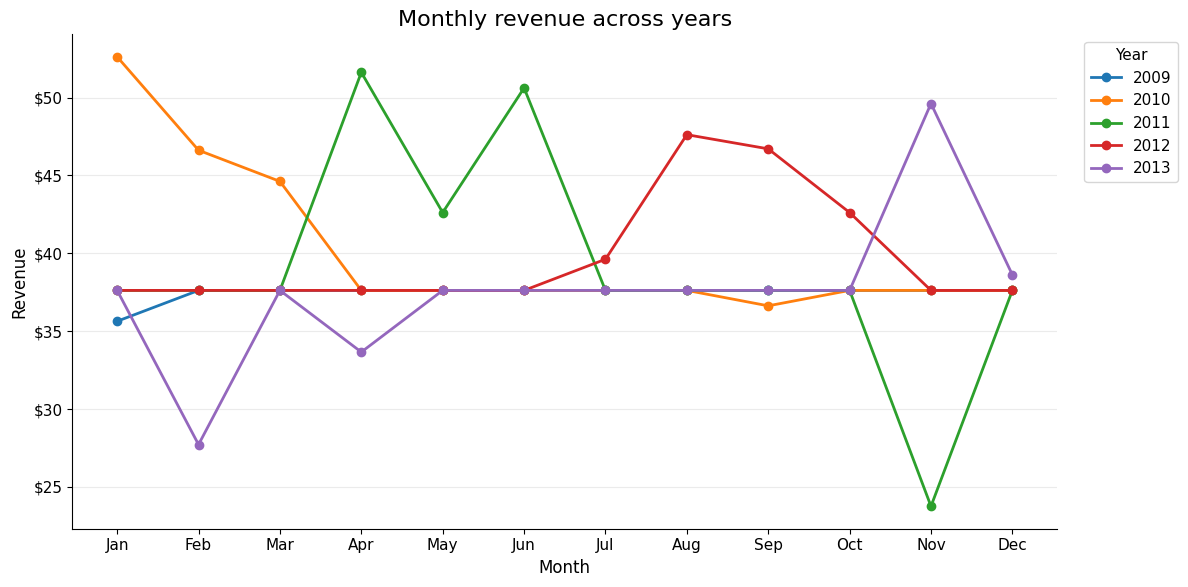

In [11]:
query = """
SELECT
    strftime('%Y', InvoiceDate) AS Year,
    CAST(strftime('%m', InvoiceDate) AS INTEGER) AS Month,
    SUM(Total) AS Revenue
FROM invoices
GROUP BY Year, Month
ORDER BY Year, Month;
"""

monthly_sales = pd.read_sql_query(query, conn)

fig, ax = plt.subplots(figsize=(12, 6))

for year, group in monthly_sales.groupby("Year"):
    ax.plot(
        group["Month"],
        group["Revenue"],
        marker="o",
        linewidth=2,
        label=year
    )

ax.set(
    title="Monthly revenue across years",
    xlabel="Month",
    ylabel="Revenue",
    xticks=range(1, 13),
    xticklabels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)

ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Year", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

The Catalog: What sells and what doesn't?

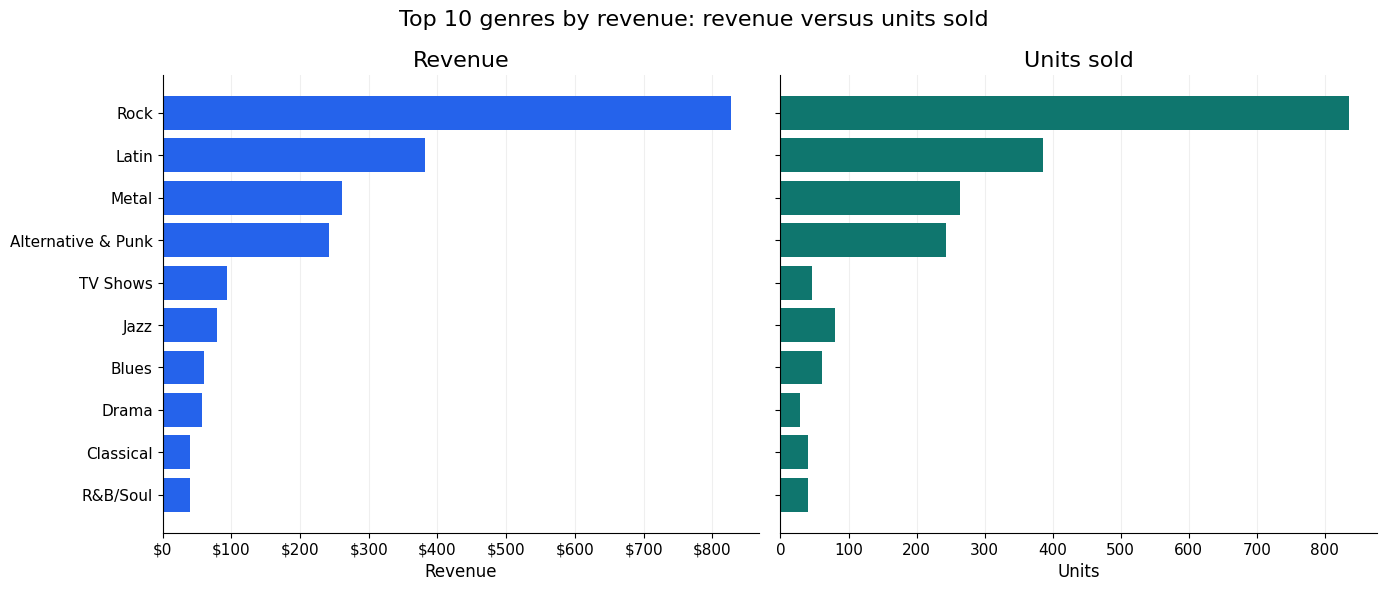

In [12]:
query = """
SELECT
    g.GenreId,
    g.Name AS Genre,
    SUM(ii.Quantity) AS UnitsSold,
    SUM(ii.UnitPrice * ii.Quantity) AS Revenue
FROM invoice_items AS ii
JOIN tracks AS t
    ON t.TrackId = ii.TrackId
JOIN genres AS g
    ON g.GenreId = t.GenreId
GROUP BY g.GenreId, g.Name
ORDER BY Revenue DESC, Genre
LIMIT 10;
"""

genre_sales = pd.read_sql_query(query, conn)

# Reverse the display order so the highest-revenue genre appears at the top.
plot_data = genre_sales.iloc[::-1]

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    sharey=True
)

axes[0].barh(
    plot_data["Genre"],
    plot_data["Revenue"],
    color="#2563EB"
)

axes[1].barh(
    plot_data["Genre"],
    plot_data["UnitsSold"],
    color="#0F766E"
)

axes[0].set(title="Revenue", xlabel="Revenue")
axes[1].set(title="Units sold", xlabel="Units")

axes[0].xaxis.set_major_formatter(
    StrMethodFormatter("${x:,.0f}")
)

for ax in axes:
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Top 10 genres by revenue: revenue versus units sold",
    fontsize=16
)

plt.tight_layout()
plt.show()

Customer Behavior: How buying habits differ.

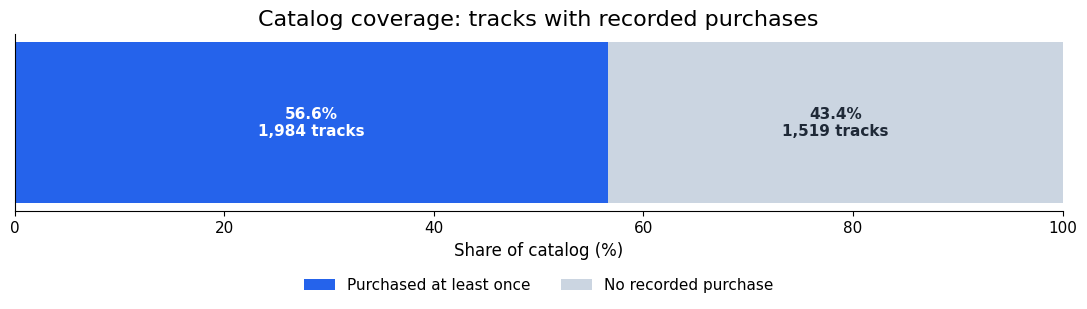

In [13]:
query = """
WITH purchased_tracks AS (
    SELECT DISTINCT TrackId
    FROM invoice_items
)
SELECT
    COUNT(pt.TrackId) AS PurchasedTracks,
    COUNT(*) - COUNT(pt.TrackId) AS NeverPurchasedTracks
FROM tracks AS t
LEFT JOIN purchased_tracks AS pt
    ON pt.TrackId = t.TrackId;
"""

catalog = pd.read_sql_query(query, conn)

purchased = int(catalog.loc[0, "PurchasedTracks"])
never_purchased = int(catalog.loc[0, "NeverPurchasedTracks"])
total = purchased + never_purchased

if total == 0:
    print("There are no catalog tracks to plot.")
else:
    counts = [purchased, never_purchased]
    labels = ["Purchased at least once", "No recorded purchase"]
    colors = ["#2563EB", "#CBD5E1"]

    fig, ax = plt.subplots(figsize=(11, 3.5))
    left = 0

    for count, label, color in zip(counts, labels, colors):
        percentage = 100 * count / total

        ax.barh(
            0,
            percentage,
            left=left,
            color=color,
            height=0.5,
            label=label
        )

        if percentage > 0:
            ax.text(
                left + percentage / 2,
                0,
                f"{percentage:.1f}%\n{count:,} tracks",
                ha="center",
                va="center",
                color="white" if color == "#2563EB" else "#1F2937",
                fontweight="bold"
            )

        left += percentage

    ax.set(
        title="Catalog coverage: tracks with recorded purchases",
        xlabel="Share of catalog (%)",
        xlim=(0, 100),
        yticks=[]
    )

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.3),
        ncol=2,
        frameon=False
    )

    plt.tight_layout()
    plt.show()

Sales Support: Customer variety by sales agent.

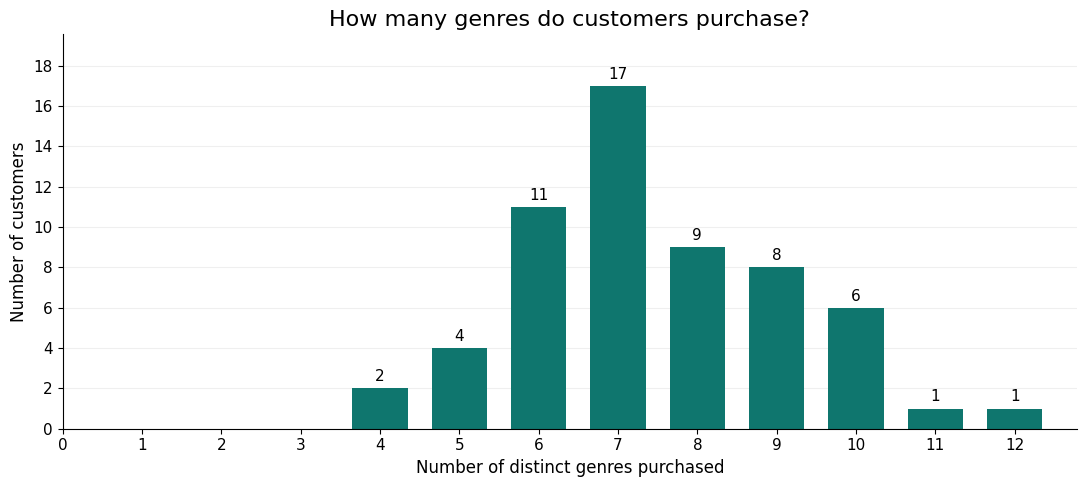

In [14]:
query = """
WITH customer_genres AS (
    SELECT
        c.CustomerId,
        COUNT(DISTINCT t.GenreId) AS DistinctGenres
    FROM customers AS c
    LEFT JOIN invoices AS i
        ON i.CustomerId = c.CustomerId
    LEFT JOIN invoice_items AS ii
        ON ii.InvoiceId = i.InvoiceId
    LEFT JOIN tracks AS t
        ON t.TrackId = ii.TrackId
    GROUP BY c.CustomerId
)
SELECT
    DistinctGenres,
    COUNT(*) AS CustomerCount
FROM customer_genres
GROUP BY DistinctGenres
ORDER BY DistinctGenres;
"""

genre_variety = pd.read_sql_query(query, conn)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    genre_variety["DistinctGenres"],
    genre_variety["CustomerCount"],
    color="#0F766E",
    width=0.7
)

ax.bar_label(bars, padding=3, fmt="%.0f")

ax.set(
    title="How many genres do customers purchase?",
    xlabel="Number of distinct genres purchased",
    ylabel="Number of customers",
    xticks=range(
        0,
        int(genre_variety["DistinctGenres"].max()) + 1
    )
)

ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.margins(y=0.15)

plt.tight_layout()
plt.show()